##### Introduction to Artificial Intelligence
## Lab 07
This lab covers adversial searches

#### Adversial Searches

**Lab Outcomes**
* Explain adversarial search and the role of competing agents.
* Represent a game as a search tree.
* Implement Minimax to determine the best possible move.
* Alpha-Beta Pruning to skip unnecessary branches.
* Compare the number of nodes explored by both algorithms.

#### Adversial Search:
The basic idea of adversarial search: searching for the best action in an environment where another agent is actively trying to achieve a competing goal.
Unlike ordinary search, where an algorithm might simply look for a path to a destination, adversarial search must consider what the opponent will do in response.\
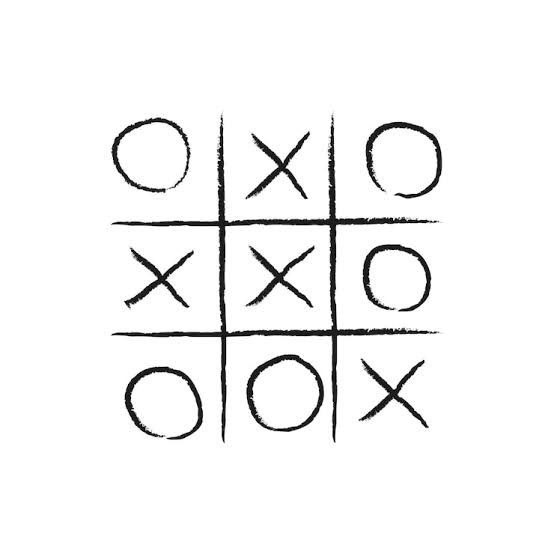

Outcome	Example utility
	+1
	0
	-1

| Outcome Example | Utility |
| :--- | :---: |
| MAX wins | +1 |
| Draw | 0 |
| MAX loses | -1 |
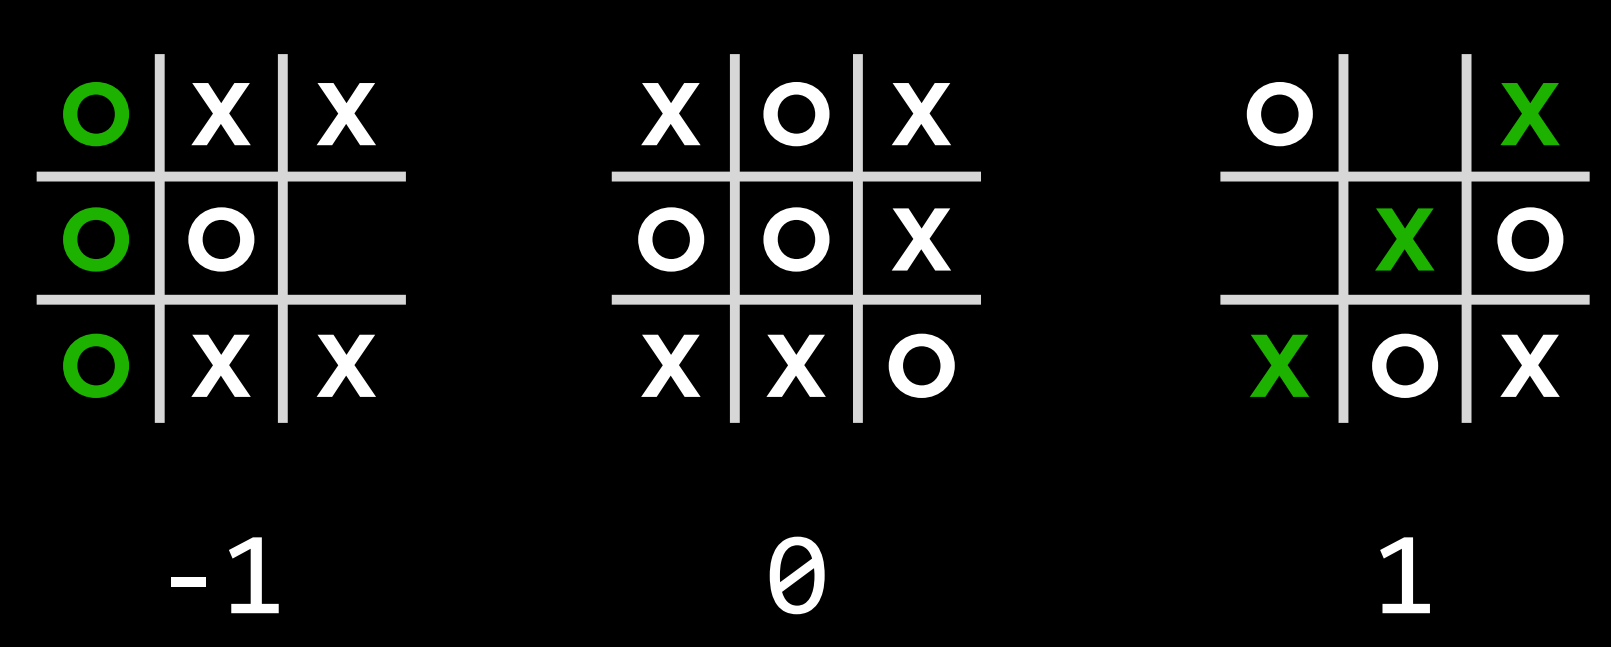

Suppose you are playing a game and can choose between three moves. Each move gives your opponent several possible responses.
You should not choose a move just because it has one excellent possible outcome. You should consider the opponent's best response against you.
Minimax follows this strategy:
- MAX chooses the move with the highest achievable guaranteed score, assuming MIN plays optimally.
- MIN chooses the move with the lowest score for MAX, assuming MAX plays optimally afterward.
Think of it as asking:\
“If I make this move, what is the worst result my opponent can force me into?”
Then choose the move whose worst-case result is best for you.

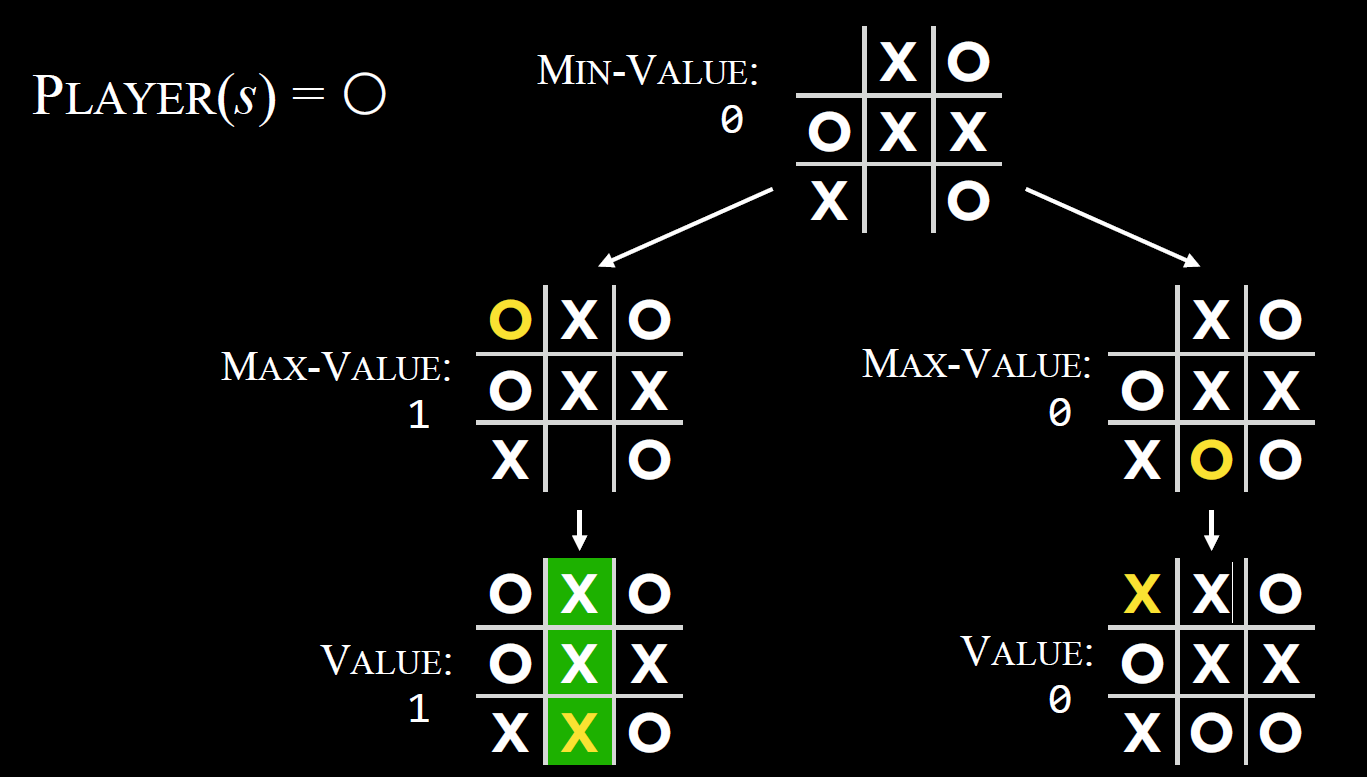

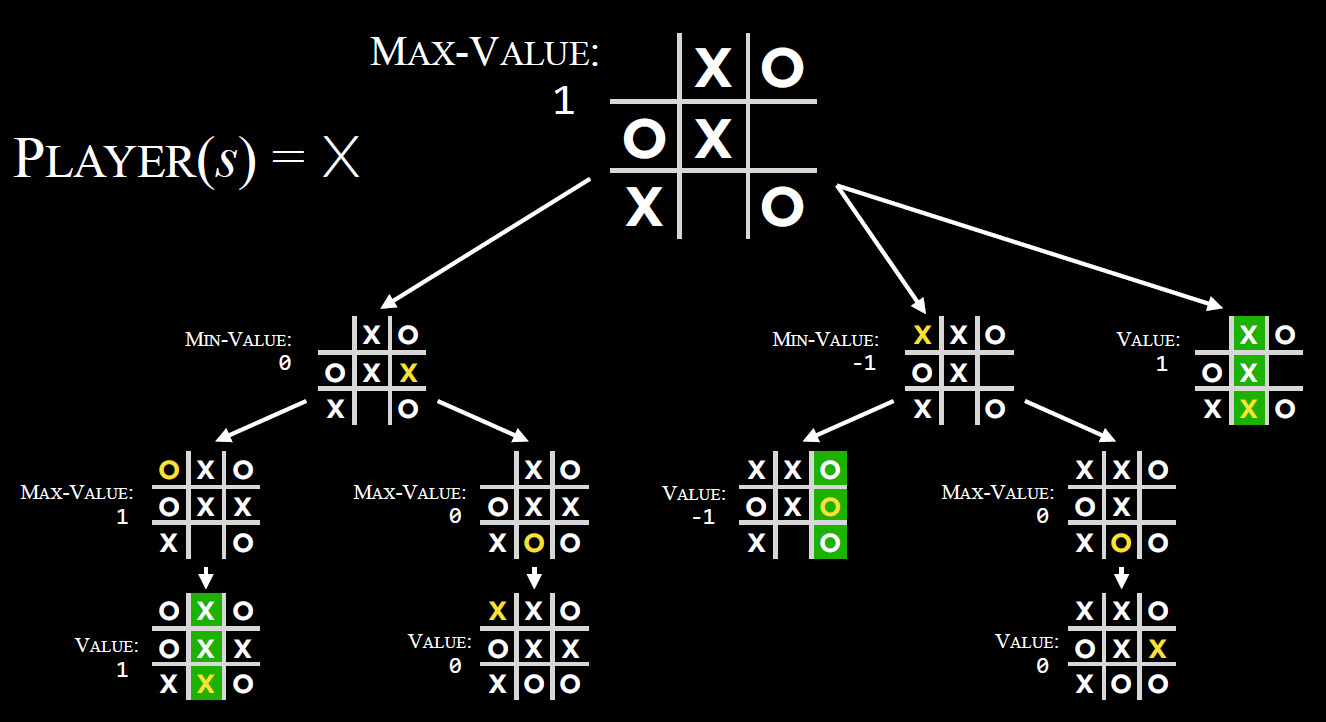

Converting the states diagram to the scores only\
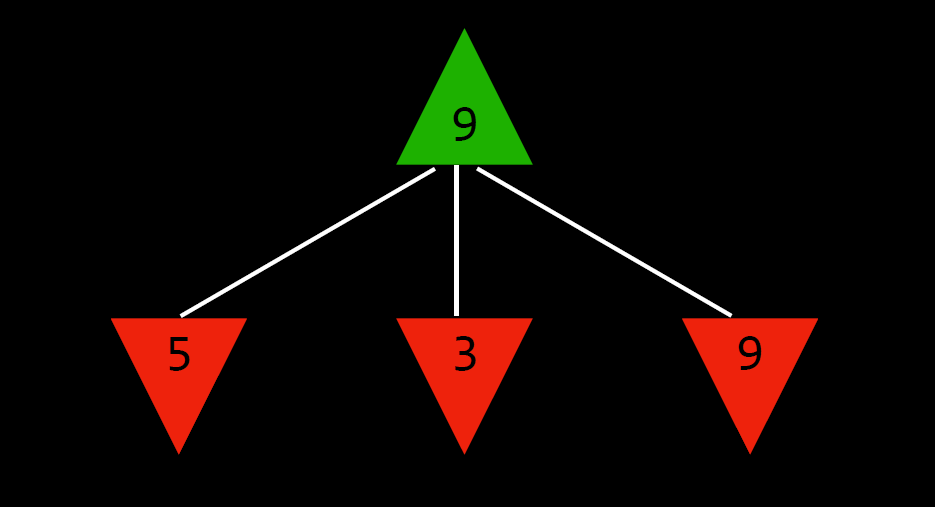

To make the decision about this point, the agents will look ahead to see what the other agent might do.\
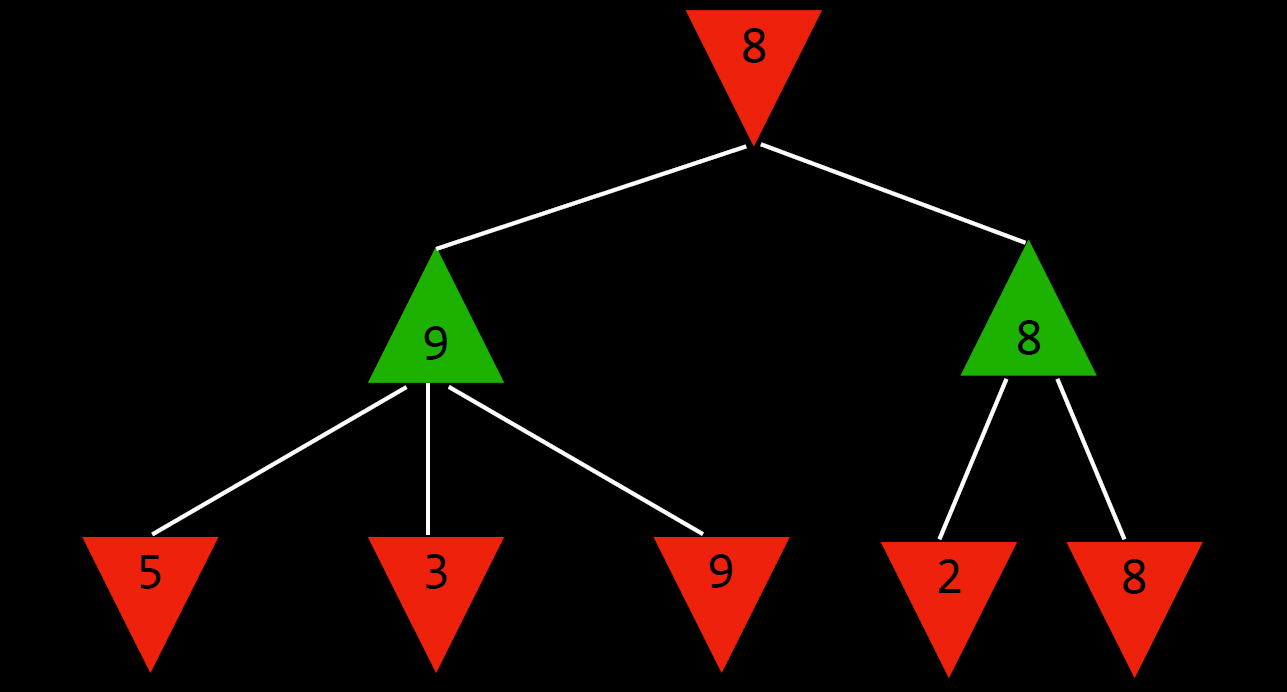





#### Minimax in Python
Now
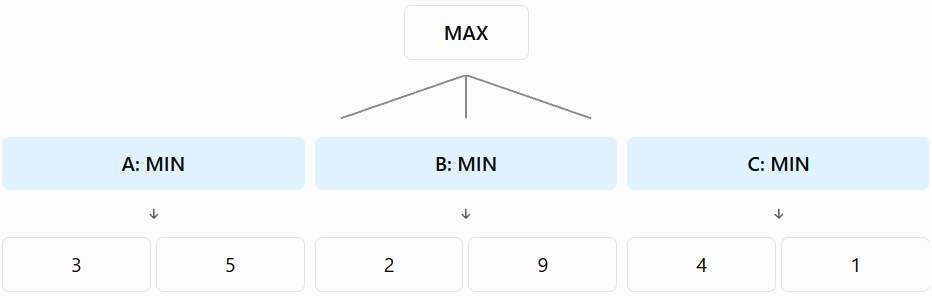

In [ ]:
#Understanding Max : Max is our maximizing agent

#To select the highest score, it will eventually use:
#max(value1, value2)
max(3, 5)  # 5

In [ ]:
#Understanding Min : Min is our mniimizing agent

#To select the lowest score, it will eventually use:
#min(value1, value2)
min(3, 5)  # 3

In [4]:
#Evaluate each move -> min(3,5) min(2,9) min(4,1)
max(3, 2, 1)  # 3

In [ ]:
#Representing the game tree 
game_tree = {
    "A": [3, 5],
    "B": [2, 9],
    "C": [4, 1]
}

In [2]:
#Write the function 
#node means the current game state , agent : True (maximizer)   False (minimizer)
def minimax(node, agent):
    pass

In [ ]:
#Base condition
if isinstance(node, int):
    return node

#node = 42
#print(isinstance(node, int))  # Output: True

In [ ]:
#For maximizer agent
if agent:
    best_value = float("-inf") # negative infinity because any number would be greater than -inf
    #Loop to go through all the possible states 
    for child in node:
        value = minimax(child, False)
        best_value = max(best_value, value)

    return best_value

In [ ]:
#For minimizing agent
else:
    best_value = float("inf") #start with infinity because any number would be less than inf

    for child in node:
        value = minimax(child, True)
        best_value = min(best_value, value)

    return best_value

In [ ]:
#Solve The Game
score = minimax(game_tree["A"], False)

In [3]:
#Run this cell 
#Combined code for Minimax

# MINIMAX ALGORITHM
# MAX wants the highest score.
# MIN wants the lowest score.
# Every leaf contains a utility score for MAX.

game_tree = {
    "A": [3, 5],
    "B": [2, 9],
    "C": [4, 1]
}

# Count how many nodes the algorithm visits.
nodes_visited = 0


def minimax(node, is_maximizing):
    global nodes_visited
    nodes_visited += 1

    # BASE CASE:
    # If node is an integer, it is a leaf containing a score.
    if isinstance(node, int):
        print(f"Evaluating leaf: {node}")
        return node

    # MAX chooses the largest value.
    if is_maximizing:
        best_value = float("-inf")

        for child in node:
            # After MAX's turn, it is MIN's turn.
            value = minimax(child, False)

            # Keep the highest value found so far.
            best_value = max(best_value, value)

        print(f"MAX returns: {best_value}")
        return best_value

    # MIN chooses the smallest value.
    else:
        best_value = float("inf")

        for child in node:
            # After MIN's turn, it is MAX's turn.
            value = minimax(child, True)

            # Keep the lowest value found so far.
            best_value = min(best_value, value)

        print(f"MIN returns: {best_value}")
        return best_value


# Evaluate each possible move separately.
best_move = None
best_score = float("-inf")

for move, children in game_tree.items():
    print(f"\nExploring move {move}")

    score = minimax(children, False)
    print(f"Move {move} has value {score}")

    # MAX selects the move with the highest Minimax value.
    if score > best_score:
        best_score = score
        best_move = move

print("\n----- FINAL RESULT -----")
print("Best move:", best_move)
print("Best score:", best_score)
print("Total nodes visited:", nodes_visited)

#Expected Output : The leaf evaluation order is 3, 5, 2, 9, 4, 1


Exploring move A
Evaluating leaf: 3
Evaluating leaf: 5
MIN returns: 3
Move A has value 3

Exploring move B
Evaluating leaf: 2
Evaluating leaf: 9
MIN returns: 2
Move B has value 2

Exploring move C
Evaluating leaf: 4
Evaluating leaf: 1
MIN returns: 1
Move C has value 1

----- FINAL RESULT -----
Best move: A
Best score: 3
Total nodes visited: 9


### Alpha Beta Pruning
Alpha–beta pruning is an optimization algorithm for the Minimax Algorithm in two-player adversarial games (like chess, tic-tac-toe, or Connect 4) that skips branches of the game tree incapable of altering the final decision.
Alpha - Maximizers' best option
Beta - Minimizer's best option


In [ ]:
#Initially no player has a useful score limit
alpha = float("-inf")
beta = float("inf")

In [ ]:
#if Maximizer's lower bound has passed minimizer's upper bound -> stop exploring this branch
if alpha >= beta:
    break

In [ ]:
# add alpha beta to the function
def alpha_beta(node, alpha, beta, agent):

In [ ]:
value = float("-inf")

for child in node:
    child_value = alpha_beta(
        child, alpha, beta, False
    )

    value = max(value, child_value)
    alpha = max(alpha, value)

    if alpha >= beta:
        break

return value

In [ ]:
value = float("inf")

for child in node:
    child_value = alpha_beta(
        child, alpha, beta, True
    )

    value = min(value, child_value)
    beta = min(beta, value)

    if alpha >= beta:
        break

return value

In [4]:

# ALPHA-BETA PRUNING
# Alpha = best value MAX can guarantee so far.
# Beta  = best (lowest) value MIN can guarantee so far.
# If alpha >= beta, the remaining children can be pruned.

game_tree = {
    "A": [3, 5],
    "B": [2, 9],
    "C": [4, 1]
}

nodes_visited = 0


def alpha_beta(node, alpha, beta, is_maximizing):
    global nodes_visited
    nodes_visited += 1

    # BASE CASE:
    # An integer represents a leaf's utility score.
    if isinstance(node, int):
        print(f"Evaluating leaf: {node}")
        return node

    # MAX tries to obtain the largest possible score.
    if is_maximizing:
        value = float("-inf")

        for child in node:
            # Search the child, switching to MIN's turn.
            child_value = alpha_beta(
                child, alpha, beta, False
            )

            value = max(value, child_value)

            # Update MAX's best known alternative.
            alpha = max(alpha, value)

            # MIN already has an alternative no better
            # than alpha, so further children are unnecessary.
            if alpha >= beta:
                print("Pruning remaining children at MAX")
                break

        print(f"MAX returns: {value}")
        return value

    # MIN tries to obtain the smallest score for MAX.
    else:
        value = float("inf")

        for child in node:
            # Search the child, switching to MAX's turn.
            child_value = alpha_beta(
                child, alpha, beta, True
            )

            value = min(value, child_value)

            # Update MIN's best known alternative.
            beta = min(beta, value)

            # MAX already has an alternative at least as good
            # as beta, so further children are unnecessary.
            if alpha >= beta:
                print("Pruning remaining children at MIN")
                break

        print(f"MIN returns: {value}")
        return value


# Evaluate each possible move.
best_move = None
best_score = float("-inf")
alpha = float("-inf")
beta = float("inf")

for move, children in game_tree.items():
    print(f"\nExploring move {move}")

    score = alpha_beta(children, alpha, beta, False)
    print(f"Move {move} has value {score}")

    # MAX keeps the best move found so far.
    if score > best_score:
        best_score = score
        best_move = move

    # Pass MAX's improved bound to the next root branch.
    alpha = max(alpha, best_score)

print("\n----- FINAL RESULT -----")
print("Best move:", best_move)
print("Best score:", best_score)
print("Total nodes visited:", nodes_visited)



Exploring move A
Evaluating leaf: 3
Evaluating leaf: 5
MIN returns: 3
Move A has value 3

Exploring move B
Evaluating leaf: 2
Pruning remaining children at MIN
MIN returns: 2
Move B has value 2

Exploring move C
Evaluating leaf: 4
Evaluating leaf: 1
Pruning remaining children at MIN
MIN returns: 1
Move C has value 1

----- FINAL RESULT -----
Best move: A
Best score: 3
Total nodes visited: 8


https://www.geeksforgeeks.org/artificial-intelligence/mini-max-algorithm-in-artificial-intelligence/